# SupeRR Selector, Season 2 · Round 1
## Who performs best under pressure? A summary of findings

**Dipmalya Chakraborty** · Rajasthan Royals SupeRR Selector (Unstop) · Round 1

This notebook is the front page of the repository. It walks through the whole story in four steps,
from *what pressure looks like* to *who handles it best* to *what Rajasthan Royals should do about it*.

| Part | Question it answers | Type of analysis |
|---|---|---|
| **1. Describe** | What does a high-pressure ball look like in IPL data? | Descriptive |
| **2. Diagnose** | Why do we define and price pressure this way? Which tempting ideas failed? | Diagnostic |
| **3. Rank** | Who are the top 10 batters and top 10 bowlers under pressure? | Descriptive and inferential |
| **4. Predict** | How sure are we, and what is the chance each pick is truly top 10? | Predictive (simulation) |
| **5. Act** | Where is Rajasthan Royals weak, and who fills the gap? | Prescriptive |

**How to use it.** Run the cells top to bottom (*Kernel → Restart & Run All*). Every chart is explained in plain words
underneath, so you can also just scroll. The notebook reads one small results file,
`pressure_rating_results.json`, which holds the outputs of the full pipeline (win-probability model,
leverage, ratings, simulations). That keeps this page fast and reproducible. The heavy lifting, from raw ball-by-ball
data to these results, lives in the other notebooks and scripts in this repository.

## The idea in one minute

* **Leverage.** For every ball we ask: *how much could this single ball swing the chance of winning?* We call that
  the **leverage index (LI)** and scale it so the average ball is 1.00. A last-over ball with 6 needed off 3 can be worth ten times an average ball.
* **Pressure ball.** The top 20% of balls by leverage (LI of 1.23 or more), **and** the player's own side is not cruising
  (batting side win chance of 60% or less; for the bowler, 40% or more). A ball where the game is already decided does not test anyone.
* **Rating.** On each pressure ball we compare what happened with what a typical player would produce there
  (runs and wickets, each wicket priced by phase). The surplus, per 100 balls for batters and per 24 balls for bowlers,
  is the **pressure rating**.
* **Honest uncertainty.** Ratings are shrunk toward the average for small samples, and every player gets an 80% interval
  and a **chance of being a true top 10** from 4,000 simulated re-draws.
* **Selection rule.** A pick must be top 10 under **at least 2 of 4** definitions of pressure (top 15, 20, 25 and 30% of balls).
  This stops the list depending on one arbitrary cut-off.

## 0 · Setup

In [1]:
# ------------------------------------------------------------------
# Libraries. Nothing exotic: pandas for tables, numpy for the maths,
# matplotlib for charts.
# ------------------------------------------------------------------
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch
from IPython.display import display, Markdown

# Rajasthan Royals palette (pink and royal blue) on a warm beige page.
PINK, BLUE, GREEN, RED, AMBER, GREY, INK = "#EA1A85", "#254AA5", "#2E9E6E", "#D64545", "#D9A441", "#A8997F", "#1B2340"
BEIGE, CARD = "#F4EDE1", "#FFFCF7"
mpl.rcParams.update({
    "figure.facecolor": BEIGE, "axes.facecolor": CARD, "savefig.facecolor": BEIGE,
    "axes.edgecolor": "#D9CDB8", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#EADFCB", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "legend.frameon": False,
})
TIER_COL = {"A": PINK, "B": BLUE, "C": GREY}

# Find the results file whether the notebook is run from the repo root, /notebooks or /data.
for p in ["pressure_rating_results.json", "data/pressure_rating_results.json", "../data/pressure_rating_results.json"]:
    if os.path.exists(p):
        D = json.load(open(p)); print("Loaded", p); break
else:
    raise FileNotFoundError("Put pressure_rating_results.json next to this notebook or in a data/ folder.")

bat, bowl = pd.DataFrame(D["lists"]["bat"]), pd.DataFrame(D["lists"]["bowl"])
def short(n):                       # "Vaibhav Sooryavanshi" -> "V. Sooryavanshi"
    p = n.split(); return n if len(p) == 1 else p[0][0] + ". " + " ".join(p[1:])
print(f"{len(bat)} batters and {len(bowl)} bowlers on the shortlists; "
      f"{len(D['pool_bat'])} batters and {len(D['pool_bowl'])} bowlers were eligible.")

Loaded pressure_rating_results.json
20 batters and 20 bowlers on the shortlists; 130 batters and 139 bowlers were eligible.


## Headline results

In [2]:
# The two final top-10 lists, side by side. "Top 10 in" counts how many of the 4 pressure cut-offs put the player in the top 10.
def top10(df, unit):
    t = df[df.status == "pick"].copy()
    t["Player"] = t.name; t["Team"] = t.team.replace("", "no IPL team")
    t[f"Rating ({unit})"] = t.rating; t["80% interval"] = t.lo.round(1).astype(str) + " to " + t.hi.round(1).astype(str)
    t["Chance of true top 10"] = t.p10.astype(str) + "%"; t["Tier"] = t.tier; t["Top 10 in"] = t.of4.astype(str) + " of 4"
    return t[["Player", "Team", f"Rating ({unit})", "80% interval", "Chance of true top 10", "Tier", "Top 10 in"]].reset_index(drop=True).rename(lambda i: i + 1)
display(Markdown("### Top 10 batters (runs above par per 100 pressure balls)")); display(top10(bat, "per 100 balls"))
display(Markdown("### Top 10 bowlers (runs above par per 24 pressure balls)")); display(top10(bowl, "per 24 balls"))
res = bat[bat.status == "reserve"].name.tolist()
print("Reserve batter(s):", ", ".join(res) if res else "none")

### Top 10 batters (runs above par per 100 pressure balls)

,Player,Team,Rating (per 100 balls),80% interval,Chance of true top 10,Tier,Top 10 in
1,Vaibhav Sooryavanshi,RR,41.8,26.1 to 57.5,95%,A,4 of 4
2,Tim David,RCB,28.5,14.3 to 42.7,76%,A,4 of 4
3,Suryakumar Yadav,MI,28.3,16.3 to 40.4,78%,A,4 of 4
4,Rajat Patidar,RCB,21.4,5.5 to 37.3,51%,B,3 of 4
5,Phil Salt,RCB,20.8,7.1 to 34.5,50%,B,4 of 4
6,Heinrich Klaasen,SRH,18.8,4.2 to 33.4,44%,B,4 of 4
7,Priyansh Arya,PBKS,18.0,1.4 to 34.7,41%,B,3 of 4
8,Nicholas Pooran,LSG,15.9,3.1 to 28.7,31%,B,2 of 4
9,Shivam Dube,CSK,14.7,0.3 to 29.1,28%,C,2 of 4
10,Abhishek Sharma,SRH,14.4,2.1 to 26.6,25%,C,3 of 4


### Top 10 bowlers (runs above par per 24 pressure balls)

,Player,Team,Rating (per 24 balls),80% interval,Chance of true top 10,Tier,Top 10 in
1,Jasprit Bumrah,MI,5.8,4.0 to 7.6,98%,A,4 of 4
2,Sunil Narine,KKR,4.1,2.3 to 6.0,80%,A,4 of 4
3,Nathan Ellis,CSK,3.0,1.0 to 5.0,54%,B,4 of 4
4,Matheesha Pathirana,KKR,2.9,1.0 to 4.8,52%,B,4 of 4
5,Bhuvneshwar Kumar,RCB,2.7,1.0 to 4.4,43%,B,4 of 4
6,Rashid Khan,GT,2.6,1.0 to 4.3,42%,B,3 of 4
7,Mustafizur Rahman,KKR,2.4,0.6 to 4.3,37%,B,3 of 4
8,Eshan Malinga,SRH,2.4,0.4 to 4.5,40%,B,3 of 4
9,Blessing Muzarabani,KKR,2.4,0.3 to 4.5,39%,B,4 of 4
10,Varun Chakravarthy,KKR,1.7,-0.0 to 3.5,20%,C,3 of 4


Reserve batter(s): Jos Buttler


**Reading the tables.** *Tier A* means more than a 60% chance of being a true top 10, *B* is 30 to 60%, *C* is below 30%.
Order inside Tiers B and C is soft because sample sizes are small; the intervals say so openly. A rating of +20 means
that player added about 20 runs more than a typical player would over 100 pressure balls.

---
# Part 1 · Describe: what does pressure look like?

### 1.1 From every ball to the balls that count

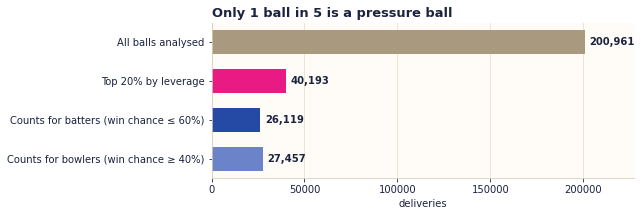

In [3]:
F = D["funnel"]
steps = [("All balls analysed", F["total"], GREY), ("Top 20% by leverage", F["top20"], PINK),
         ("Counts for batters (win chance ≤ 60%)", F["bat"], BLUE), ("Counts for bowlers (win chance ≥ 40%)", F["bowl"], "#6B84C9")]
fig, ax = plt.subplots(figsize=(9, 3.1))
for i, (lab, v, c) in enumerate(steps):
    ax.barh(i, v, color=c, height=0.62); ax.text(v + 2500, i, f"{v:,}", va="center", fontweight="bold")
ax.set_yticks(range(4)); ax.set_yticklabels([s[0] for s in steps]); ax.invert_yaxis(); ax.set_xlim(0, F["total"] * 1.13)
ax.set_title("Only 1 ball in 5 is a pressure ball"); ax.grid(axis="y", visible=False); ax.set_xlabel("deliveries")
plt.tight_layout(); plt.show()

**So what.** We start with 200,961 analysed deliveries (200,999 raw rows, minus 38 super-over balls kept out because
they follow different rules). About 40,000 are high-leverage. A batter is judged only on those where his side still needs something
from him, and a bowler only on those where the batting side still has a chance. Small samples are the price of being strict, which is why uncertainty is a theme throughout.

### 1.2 How unevenly is the drama spread?

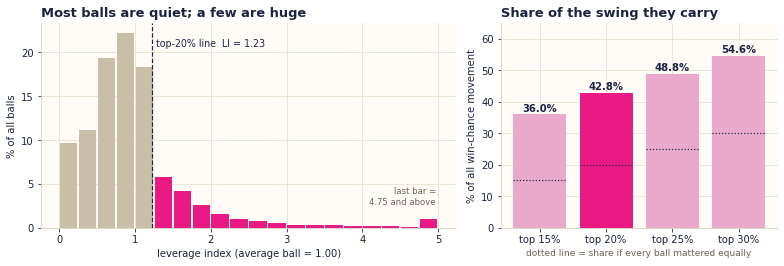

Median ball LI = 0.81, 90th percentile = 1.69, 99th percentile = 4.85, maximum = 20.3


In [4]:
L = D["lev"]; edges = np.array(L["edges"]); share = np.array(L["share"]); mid = (edges[:-1] + edges[1:]) / 2
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
cols = [PINK if lo >= L["thr"]["20"] else "#C9BEA8" for lo in edges[:-1]]
ax[0].bar(mid, share, width=0.23, color=cols)
ax[0].axvline(L["thr"]["20"], color=INK, ls="--", lw=1.2); ax[0].text(L["thr"]["20"] + .05, share.max() * .93, f"top-20% line  LI = {L['thr']['20']}", fontsize=9.5)
ax[0].text(4.97, share.max() * .12, "last bar =\n4.75 and above", ha="right", fontsize=8.5, color="#6B6254"); ax[0].set_xlabel("leverage index (average ball = 1.00)"); ax[0].set_ylabel("% of all balls"); ax[0].set_title("Most balls are quiet; a few are huge")
cut = ["15", "20", "25", "30"]; v = [L["dwp_share"][k] for k in cut]
ax[1].bar([f"top {k}%" for k in cut], v, color=[PINK if k == "20" else "#E9A9CB" for k in cut])
for i, k in enumerate(cut): ax[1].plot([i - .4, i + .4], [int(k)] * 2, color=INK, lw=1.2, ls=":")
for i, x in enumerate(v): ax[1].text(i, x + 1, f"{x:.1f}%", ha="center", fontweight="bold")
ax[1].set_ylim(0, 65); ax[1].set_ylabel("% of all win-chance movement"); ax[1].set_title("Share of the swing they carry")
ax[1].set_xlabel("dotted line = share if every ball mattered equally", fontsize=9, color="#6B6254")
plt.tight_layout(); plt.show()
print(f"Median ball LI = {D['ins']['lev_q']['p50']}, 90th percentile = {D['ins']['lev_q']['p90']}, 99th percentile = {D['ins']['lev_q']['p99']}, maximum = {D['ins']['lev_q']['max']}")

**So what.** The top 20% of balls carry **42.8%** of all the movement in win chance, **2.1×** their fair share. That is the quantitative reason to
single them out: pressure is concentrated, so judging players on all balls dilutes the signal. The right panel also shows why we test 15, 25 and 30% as well:
the share rises smoothly, so there is no magic cut-off and no reason to bet the whole list on one.

### 1.3 When does pressure show up?

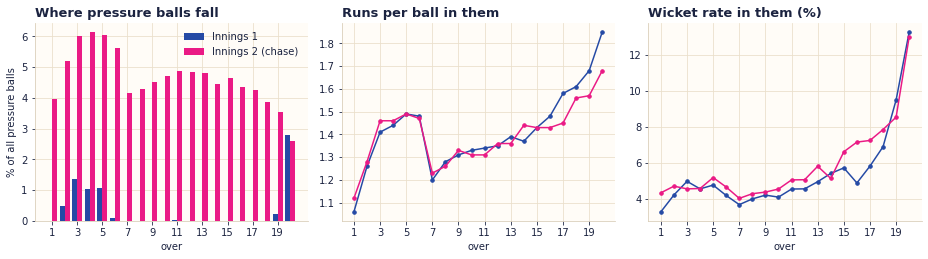

innings,phase,pressure_share_%,balls,pressure_balls
1st innings,powerplay,5.0,"32,377","1,627"
1st innings,middle,0.0,"47,391",13
1st innings,death,4.6,"25,959","1,206"
2nd innings (chase),powerplay,41.9,"31,631","13,260"
2nd innings (chase),middle,36.8,"45,108","16,615"
2nd innings (chase),death,40.4,"18,495","7,472"


Share of pressure balls by innings: {'1st': '7.1%', '2nd': '92.9%'}


In [5]:
B = pd.DataFrame(D["byover"], columns=["inn", "over", "press_share", "li", "n", "runs_per_ball", "wkt_rate"])
B["press_balls"] = B.n * B.press_share / 100
fig, ax = plt.subplots(1, 3, figsize=(13, 3.7))
for inn, c, nm in [(1, BLUE, "Innings 1"), (2, PINK, "Innings 2 (chase)")]:
    s = B[B.inn == inn]
    ax[0].bar(s.over + (-.2 if inn == 1 else .2), s.press_balls / B.press_balls.sum() * 100, width=.4, color=c, label=nm)
    ax[1].plot(s.over, s.runs_per_ball, color=c, marker="o", ms=3.5, label=nm)
    ax[2].plot(s.over, s.wkt_rate, color=c, marker="o", ms=3.5, label=nm)
ax[0].set_title("Where pressure balls fall"); ax[0].set_ylabel("% of all pressure balls"); ax[1].set_title("Runs per ball in them"); ax[2].set_title("Wicket rate in them (%)")
for a in ax: a.set_xlabel("over"); a.set_xticks(range(1, 21, 2))
ax[0].legend(); plt.tight_layout(); plt.show()
ph = pd.DataFrame(D["ins"]["phase"], columns=["innings", "phase", "pressure_share_%", "balls", "pressure_balls"])
ph["innings"] = ph.innings.map({1: "1st innings", 2: "2nd innings (chase)"})
display(ph.style.format({"pressure_share_%": "{:.1f}", "balls": "{:,}", "pressure_balls": "{:,}"}).hide(axis="index"))
print("Share of pressure balls by innings:", {("1st" if k == "1" else "2nd"): f"{v}%" for k, v in D["ins"]["inn_share"].items()})

**So what.** About **93% of pressure balls come in the chase**. This is not a modelling quirk: in the first innings nobody knows what a winning total is,
so a single ball rarely moves the win chance much, whereas in a chase the target is fixed and every ball counts against it.
Within the chase, pressure balls are spread across all 20 overs (roughly 4 to 6% of the total in each, a little more in overs 2 to 6). What changes is the intensity: in the right-hand panels, runs per ball and the wicket rate on pressure balls climb steeply towards the death (about 13 wickets per 100 balls in over 20). So a pressure specialist is not simply a death-over specialist. The first-innings middle overs almost never produce pressure balls (13 of 47,391), which matters for how we read first-innings batting later.

### 1.4 The leverage map: when is a ball most dangerous?

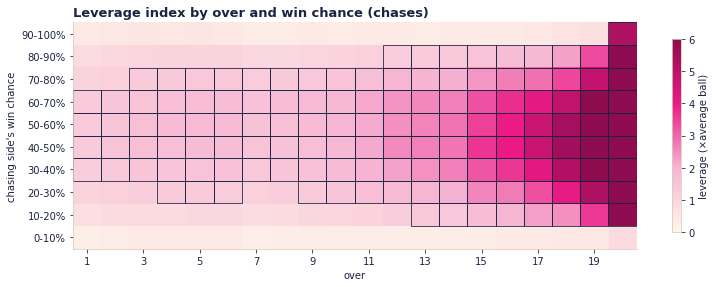

In [6]:
H = pd.DataFrame(D["heat"]["cells"], columns=["band", "over", "li", "n"])
M = H[H.n >= 30].pivot(index="band", columns="over", values="li").reindex(index=range(9, -1, -1), columns=range(1, 21))
fig, ax = plt.subplots(figsize=(11, 4.1))
from matplotlib.colors import LinearSegmentedColormap
cm = LinearSegmentedColormap.from_list("rr", ["#FFF6EA", "#F6B3D2", PINK, "#8E0B4F"])
im = ax.imshow(M.values, aspect="auto", cmap=cm, vmin=0, vmax=6)
ax.set_xticks(range(0, 20, 2)); ax.set_xticklabels(range(1, 21, 2)); ax.set_yticks(range(10)); ax.set_yticklabels([f"{b*10}-{b*10+10}%" for b in M.index])
ax.set_xlabel("over"); ax.set_ylabel("chasing side's win chance"); ax.set_title("Leverage index by over and win chance (chases)"); ax.grid(False)
for (r, c), v in np.ndenumerate(M.values):
    if not np.isnan(v) and v >= 1.23: ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fill=False, ec=INK, lw=.8))
plt.colorbar(im, label="leverage (×average ball)", shrink=.85); plt.tight_layout(); plt.show()

**So what.** Leverage builds through the innings and peaks in the last over. Outlined cells clear the pressure line (LI of 1.23 or more); they cover close games (win chance of roughly 20 to 80%) from the middle overs onward and, late on, almost the whole band. Early in the innings, and whenever a chase is nearly won or nearly lost, one ball can no longer change the outcome much, so leverage is low and those balls are not tested. This picture is exactly what the rating uses to decide whose runs and wickets "count".

### 1.5 Do pressure balls play differently from ordinary ones?

,Balls,Runs per ball,Wickets per 100 balls,Dot-ball %,Boundary %
Ordinary balls,"160,768.0",1.38,5.26,37.2,18.3
Pressure balls,"40,193.0",1.45,6.01,36.3,20.0


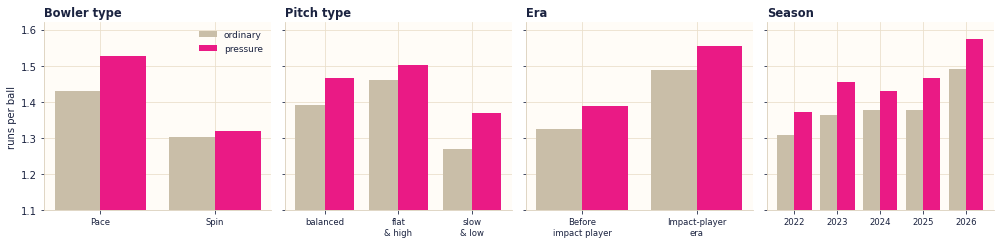

In [7]:
pv = D["ins"]["pv"]
tbl = pd.DataFrame({"Ordinary balls": pv["ord"], "Pressure balls": pv["press"]}).T
tbl.columns = ["Balls", "Runs per ball", "Wickets per 100 balls", "Dot-ball %", "Boundary %"]
display(tbl.style.format({"Balls": "{:,}", "Runs per ball": "{:.2f}", "Wickets per 100 balls": "{:.2f}", "Dot-ball %": "{:.1f}", "Boundary %": "{:.1f}"}))

def seg(items, key):  # pressure vs ordinary runs-per-ball for a list of segments
    return pd.DataFrame([{"seg": i["k"] if "k" in i else str(i["y"]), "press": i["press"][key], "ord": i["ord"][key]} for i in items])
panels = [("Bowler type", D["ins"]["ps"]), ("Pitch type", D["ins"]["pitch"]), ("Era", D["ins"]["era"]), ("Season", D["ins"]["year"])]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for a, (t, it) in zip(ax, panels):
    s = seg(it, "rpb"); x = np.arange(len(s))
    a.bar(x - .2, s["ord"], .4, color="#C9BEA8", label="ordinary"); a.bar(x + .2, s["press"], .4, color=PINK, label="pressure")
    a.set_xticks(x); a.set_xticklabels([t_.replace(" ", "\n", 1) if len(t_) > 9 else t_ for t_ in s.seg], fontsize=8.5); a.set_title(t, fontsize=11.5); a.set_ylim(1.1, 1.62)
ax[0].set_ylabel("runs per ball"); ax[0].legend(fontsize=9); plt.tight_layout(); plt.show()

**So what.** Pressure balls yield **more runs per ball (1.45 vs 1.38) and more wickets (6.0 vs 5.3 per 100)**: batters take more risk, and it costs them more
often. The gap is present for pace and spin, on every pitch type, in every season and in the impact-player era, so the pressure effect is a general feature of the game,
not an artefact of one period. It also tells us why a flat run-rate comparison misleads: the same shot at the same score means something different at 70% win chance and at 30%.

---
# Part 2 · Diagnose: why we price pressure this way, and what did not work

### 2.1 A wicket is not a wicket: the price of a dismissal by phase

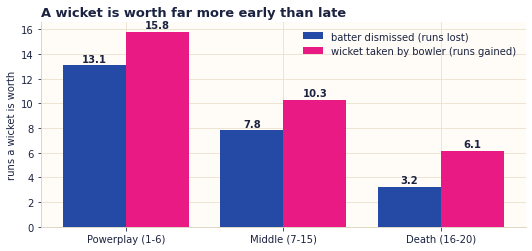

Early-to-late price ratio: batters 4.0x, bowlers 2.6x


In [8]:
W = D["wicket"]; ph = ["powerplay", "middle", "death"]; x = np.arange(3)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(x - .2, [W["bat"][p] for p in ph], .4, color=BLUE, label="batter dismissed (runs lost)")
ax.bar(x + .2, [W["bowl"][p] for p in ph], .4, color=PINK, label="wicket taken by bowler (runs gained)")
for i, p in enumerate(ph):
    ax.text(i - .2, W["bat"][p] + .3, f"{W['bat'][p]:.1f}", ha="center", fontweight="bold"); ax.text(i + .2, W["bowl"][p] + .3, f"{W['bowl'][p]:.1f}", ha="center", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(["Powerplay (1-6)", "Middle (7-15)", "Death (16-20)"]); ax.set_ylabel("runs a wicket is worth"); ax.legend(loc="upper right")
ax.set_title("A wicket is worth far more early than late"); plt.tight_layout(); plt.show()
print(f"Early-to-late price ratio: batters {W['bat']['powerplay']/W['bat']['death']:.1f}x, bowlers {W['bowl']['powerplay']/W['bowl']['death']:.1f}x")

**Why it matters.** A batter lost in the powerplay costs his side about 13 runs of expected total; a batter lost at the death costs about 3, because few
balls remain to be wasted. Pricing wickets with one flat number would reward death hitters for "not getting out" and punish openers for taking risks. Pricing by phase compares every
player with what the *situation* was worth, which is the fair test.

### 2.2 Can we trust the win-probability model?

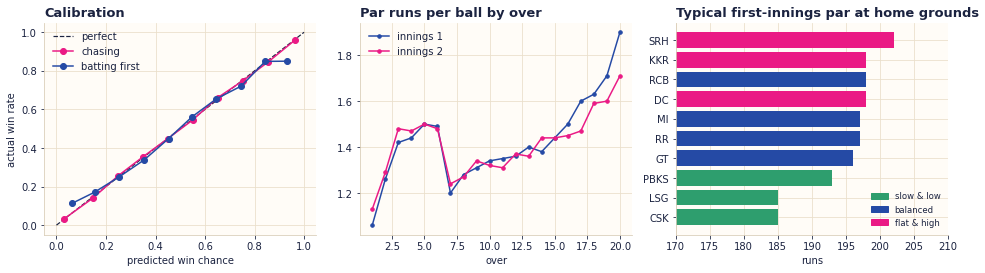

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.9))
ax[0].plot([0, 1], [0, 1], color=INK, ls="--", lw=1.2, label="perfect")
for k, c, nm in [("chase", PINK, "chasing"), ("first", BLUE, "batting first")]:
    P = np.array(D["calib"][k]); ax[0].plot(P[:, 0], P[:, 1], marker="o", color=c, label=nm)
ax[0].set_xlabel("predicted win chance"); ax[0].set_ylabel("actual win rate"); ax[0].set_title("Calibration"); ax[0].legend()
po = pd.DataFrame(D["par_over"], columns=["inn", "over", "par"]).pivot(index="over", columns="inn", values="par")
ax[1].plot(po.index, po[1], color=BLUE, marker="o", ms=3.5, label="innings 1"); ax[1].plot(po.index, po[2], color=PINK, marker="o", ms=3.5, label="innings 2")
ax[1].set_title("Par runs per ball by over"); ax[1].set_xlabel("over"); ax[1].legend()
vp = pd.DataFrame(D["venue_par"], columns=["team", "par", "type", "n"]).sort_values("par")
ab = {"Chennai Super Kings": "CSK", "Lucknow Super Giants": "LSG", "Punjab Kings": "PBKS", "Gujarat Titans": "GT", "Rajasthan Royals": "RR", "Mumbai Indians": "MI", "Delhi Capitals": "DC", "Royal Challengers Bengaluru": "RCB", "Kolkata Knight Riders": "KKR", "Sunrisers Hyderabad": "SRH"}
ax[2].barh([ab.get(t, t) for t in vp.team], vp.par, color=[{"slow & low": GREEN, "balanced": BLUE, "flat & high": PINK}[t] for t in vp.type])
ax[2].set_xlim(170, 210); ax[2].set_title("Typical first-innings par at home grounds"); ax[2].set_xlabel("runs")
ax[2].legend(handles=[Patch(color=c, label=l) for l, c in [("slow & low", GREEN), ("balanced", BLUE), ("flat & high", PINK)]], fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()

**Model quality (from the methodology run).** The chase win-probability model has **AUC 0.904 and log-loss 0.388**; the first-innings model is much weaker (**AUC 0.714**), as expected because the target is unknown.
Predictions were produced **out-of-fold, grouped by match**, so no ball was scored by a model that had seen its own match.

**Reading the charts.** Left: points hugging the dashed line mean that when the model says 30%, teams win about 30% of the time. The chase curve does; the first-innings curve is looser, which is why
first-innings pressure is treated cautiously. Middle: the par engine (what a typical player scores) rises through the innings, strongest at the death. Right: par differs by ground, from about 185 at
Chennai and Lucknow to about 202 at Hyderabad, which is why runs are always compared with par for the situation and venue rather than with a flat average. The par engine deliberately **excludes player identity**, otherwise it would absorb the player's own skill.

### 2.3 Do big matches count extra? We checked, and it made no difference to how pressure shows up

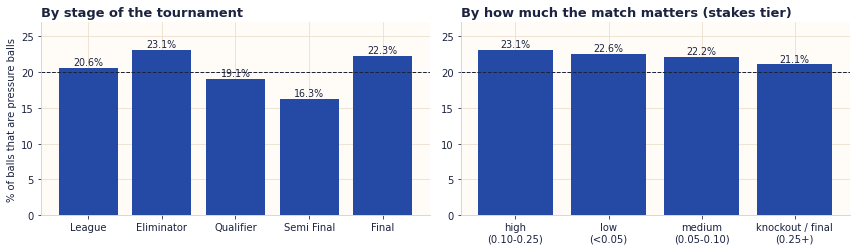

Correlation between ball leverage and match stakes: r = -0.004 (a linear measure only; the stage and tier comparisons above show the same flat picture).


In [10]:
S = pd.DataFrame(D["stakes"]).dropna(subset=["stake"]).sort_values("stake")
st = pd.DataFrame(D["stakes_tier"], columns=["tier", "balls", "press"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(S.stage, S.press, color=BLUE); ax[0].axhline(20, color=INK, ls="--", lw=1)
for i, v in enumerate(S.press): ax[0].text(i, v + .4, f"{v:.1f}%", ha="center", fontsize=9.5)
ax[0].set_ylim(0, 27); ax[0].set_ylabel("% of balls that are pressure balls"); ax[0].set_title("By stage of the tournament")
st["tier"] = st.tier.str.replace(" (", "\n(", regex=False).str.replace("sudden-death / title", "knockout / final", regex=False)
ax[1].bar(st.tier, st.press, color=BLUE); ax[1].axhline(20, color=INK, ls="--", lw=1)
for i, v in enumerate(st.press): ax[1].text(i, v + .4, f"{v:.1f}%", ha="center", fontsize=9.5)
ax[1].set_ylim(0, 27); ax[1].set_title("By how much the match matters (stakes tier)")
plt.tight_layout(); plt.show()
print(f"Correlation between ball leverage and match stakes: r = {D['stakes_corr']:+.3f} (a linear measure only; the stage and tier comparisons above show the same flat picture).")

**So what.** By our definition a final is not "more pressured" ball for ball than a league match: between about 16% and 23% of balls are pressure balls in every stage and tier, with no rise as the stakes climb (a final is 22.3%, a semi-final 16.3%). That is a statement about the
*moment*, not about how it feels. We therefore **measure stakes but do not use them to weight ratings**. Doing so would reward players for playing in big fixtures rather than for how they handled a tense ball.
Note that a near-zero correlation only rules out a straight-line relationship; the comparisons by stage and tier are the more informative check, and they are flat too.

### 2.4 A popular theory that failed its audition: do bowlers with more death-over variety save more runs?

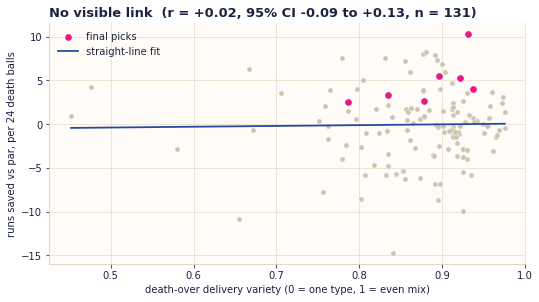

In [11]:
V = pd.DataFrame(D["variety"]["pts"], columns=["name", "variety", "saved_per24", "pick"]); st_ = D["variety"]["stats"]
fig, ax = plt.subplots(figsize=(7.6, 4.3))
ax.scatter(V.variety, V.saved_per24, s=28, color="#C9BEA8", alpha=.9, edgecolor="white", lw=.5)
pk = V[V.pick]; ax.scatter(pk.variety, pk.saved_per24, s=60, color=PINK, edgecolor="white", label="final picks")
m, c0 = np.polyfit(V.variety, V.saved_per24, 1); xs = np.linspace(V.variety.min(), V.variety.max(), 50); ax.plot(xs, m * xs + c0, color=BLUE, lw=1.8, label="straight-line fit")
ax.set_xlabel("death-over delivery variety (0 = one type, 1 = even mix)"); ax.set_ylabel("runs saved vs par, per 24 death balls"); ax.legend()
ax.set_title(f"No visible link  (r = {st_['r']:+.2f}, 95% CI {st_['lo']:+.2f} to {st_['hi']:+.2f}, n = {st_['n_bowlers']})"); plt.tight_layout(); plt.show()

**So what.** The scatter is a cloud, and the fitted line is flat. Bowlers who mix yorkers, slower balls and cutters widely do not save measurably more runs than those who stick to a stock plan.
We looked at the picture, not only the single correlation figure, because *r* measures straight-line association only. We therefore **do not rank bowlers by "variety"**; outcomes already contain whatever variety adds.

### 2.5 Where does each pick's rating come from: runs or wickets?

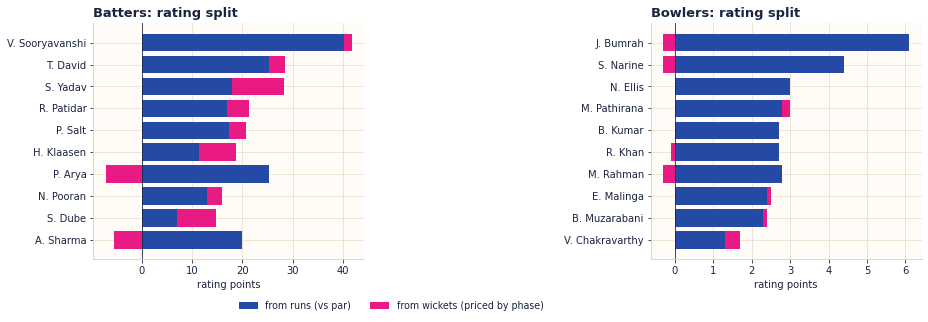

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a, df, ttl in [(ax[0], bat[bat.status == "pick"], "Batters"), (ax[1], bowl[bowl.status == "pick"], "Bowlers")]:
    d_ = df.iloc[::-1]; y = np.arange(len(d_))
    a.barh(y, d_.runPart, color=BLUE, label="from runs (vs par)")
    a.barh(y, d_.wktPart, left=np.where(d_.wktPart >= 0, d_.runPart, 0), color=PINK, label="from wickets (priced by phase)")
    a.set_yticks(y); a.set_yticklabels([short(n) for n in d_.name]); a.axvline(0, color=INK, lw=.8); a.set_title(f"{ttl}: rating split"); a.set_xlabel("rating points")
ax[0].legend(loc="upper center", bbox_to_anchor=(1.1, -.14), ncol=2, fontsize=9.5); plt.tight_layout(); plt.show()

**So what.** For almost every player the rating is overwhelmingly **runs against par**. Wickets matter more for batters than for bowlers: Suryakumar Yadav, Klaasen and Dube get a visible share of their rating from *not getting out* when it counts, while Priyansh Arya and Abhishek Sharma are the high-risk end, scoring fast enough that the cost of their dismissals (the pink bar going left) is more than covered. For bowlers the blue bars dominate: under pressure, the best bowlers earn their rating by **restricting runs** rather than taking wickets (Chakravarthy is the clearest wicket contributor). This helps with role fit: read the pink bars for who protects an innings, the blue for who scores or saves runs.

### 2.6 Is the ranking robust to how we define pressure?

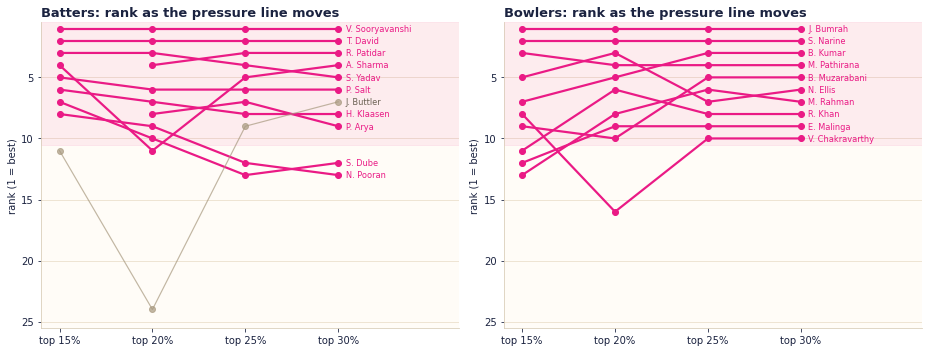

Batters passing all four cut-offs: 5 | bowlers passing all four: 6


In [13]:
CUT = ["top 15%", "top 20%", "top 25%", "top 30%"]
def rank_path(side_key, picks_only=True):
    E = pd.DataFrame(D["explorer"][side_key])
    E[CUT] = pd.DataFrame(E.ranks.tolist(), index=E.index)[[1, 0, 2, 3]].values   # stored order is [20%, 15%, 25%, 30%]
    E[CUT] = E[CUT].replace(0, np.nan)          # 0 = too few pressure balls to be ranked at that cut-off (shown as a gap)
    return E[E.pick | (E.of4 >= 2)].sort_values(CUT[1]).head(14)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, key, ttl in [(ax[0], "bat", "Batters"), (ax[1], "bowl", "Bowlers")]:
    E = rank_path(key)
    for _, r in E.iterrows():
        a.plot(range(4), r[CUT].astype(float).clip(upper=25), marker="o", color=PINK if r.pick else GREY, lw=2.2 if r.pick else 1.2, alpha=1 if r.pick else .7)
        a.text(3.08, min(r[CUT[3]], 25), short(r["name"]), fontsize=8.3, va="center", color=PINK if r.pick else "#6B6254")
    a.axhspan(.5, 10.5, color=PINK, alpha=.07); a.set_ylim(25.5, .5); a.set_xlim(-.2, 4.3); a.set_xticks(range(4)); a.set_xticklabels(CUT)
    a.set_ylabel("rank (1 = best)"); a.set_title(f"{ttl}: rank as the pressure line moves"); a.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print("Batters passing all four cut-offs:", int((bat.of4 == 4).sum()), "| bowlers passing all four:", int((bowl.of4 == 4).sum()))

**So what.** Pink lines are final picks; the shaded band is the top 10. Most picks stay in or near the band as the line moves from the top 15% to the top 30% of balls: **5 batters and 6 bowlers pass all four tests**.
The rest pass at least two, and that is the rule. A gap in a line means the player had too few pressure balls to be ranked at that cut-off (Patidar and Arya at the top 15%); ranks beyond 25 are drawn at 25 (Buttler at the top 20%). Lines that dive in or out of the band belong to players whose case depends on the exact definition; the lists keep them honest by requiring the 2-of-4 pass.

### 2.7 Do the best pressure players also play well in ordinary situations, and does it hold up season to season?

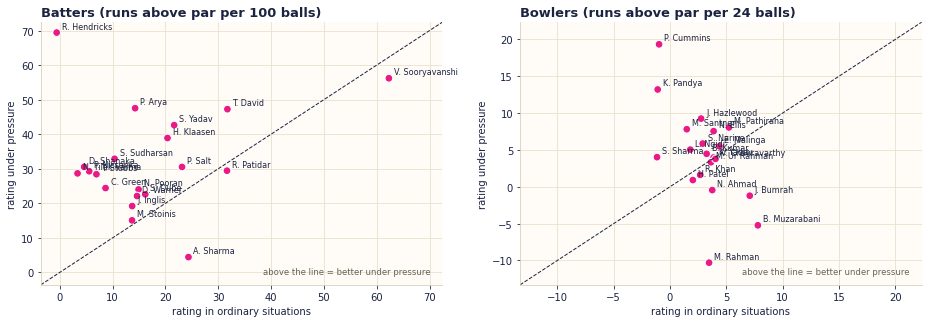

,side,pressure rating,ordinary rating,pressure minus ordinary,seasons of evidence
player,,,,,
Vaibhav Sooryavanshi,bat,56.2,62.3,-6.1,2
Tim David,bat,47.2,31.7,15.5,3
Suryakumar Yadav,bat,42.6,21.7,21.0,3
Rajat Patidar,bat,29.4,31.7,-2.2,1
Reeza Hendricks,bat,69.4,-0.6,70.0,3
Phil Salt,bat,30.5,23.2,7.4,3
Heinrich Klaasen,bat,38.9,20.4,18.5,2
Priyansh Arya,bat,47.5,14.3,33.3,2
Nicholas Pooran,bat,24.0,14.9,9.1,3


In [14]:
Cn = pd.DataFrame(D["consist"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a, side, ttl in [(ax[0], "bat", "Batters (runs above par per 100 balls)"), (ax[1], "bowl", "Bowlers (runs above par per 24 balls)")]:
    s = Cn[Cn.side == side]; lim = [min(s.uv.min(), s.pv.min()) - 3, max(s.uv.max(), s.pv.max()) + 3]
    a.plot(lim, lim, color=INK, ls="--", lw=1); a.scatter(s.uv, s.pv, s=60, c=[PINK if p <= 10 else BLUE for p in s.pos], edgecolor="white")
    for _, r in s.iterrows(): a.annotate(short(r["name"]), (r.uv, r.pv), xytext=(5, 4), textcoords="offset points", fontsize=8)
    a.set_xlabel("rating in ordinary situations"); a.set_ylabel("rating under pressure"); a.set_title(ttl); a.set_xlim(lim); a.set_ylim(lim)
    a.text(.97, .04, "above the line = better under pressure", ha="right", transform=a.transAxes, fontsize=8.5, color="#6B6254")
plt.tight_layout(); plt.show()
display(Cn.assign(player=Cn.name).set_index("player")[["side", "pv", "uv", "res", "seasons"]].rename(columns={"pv": "pressure rating", "uv": "ordinary rating", "res": "pressure minus ordinary", "seasons": "seasons of evidence"}).round(1).head(12))

**So what.** Players above the dashed line do better under pressure than in routine moments; those below are strong generally but their edge fades when it matters. The ranking is built on pressure performance alone, which is by design: the task asks who handles pressure, not who is best overall. (These per-player figures are descriptive and unshrunk, so read them as supporting evidence, not as the official rating.)

---
# Part 3 · Rank: the final lists

### 3.1 Top 20 batters with uncertainty

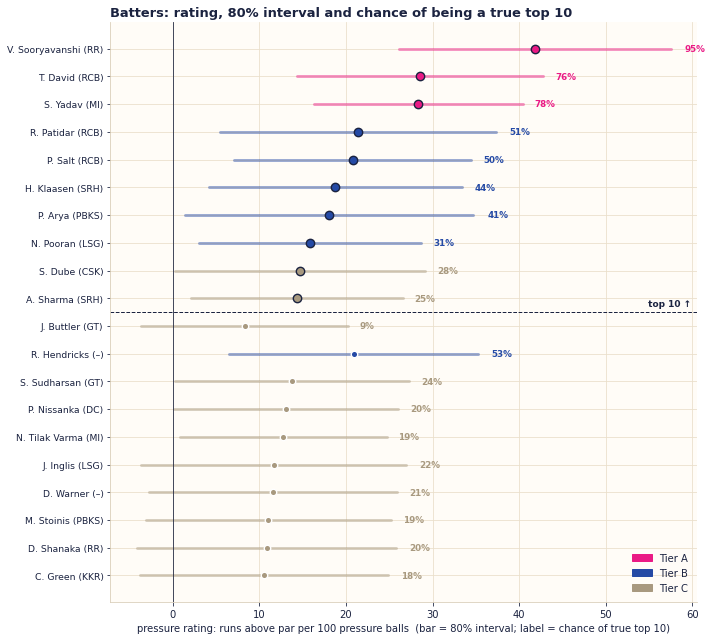

In [15]:
def forest(df, title, unit, n=20):
    d_ = df.head(n).iloc[::-1]; y = np.arange(len(d_))
    fig, ax = plt.subplots(figsize=(10, 0.36 * n + 1.8))
    for yi, (_, r) in zip(y, d_.iterrows()):
        col = TIER_COL[r.tier]; ax.plot([r.lo, r.hi], [yi, yi], color=col, lw=3, alpha=.45, solid_capstyle="round")
        ax.scatter(r.rating, yi, s=70 if r.status == "pick" else 42, color=col, edgecolor=INK if r.status == "pick" else "white", lw=1.4, zorder=3)
        ax.text(r.hi + (r.hi - r.lo) * .03 + .6, yi, f"{r.p10}%", va="center", fontsize=8.8, color=col, fontweight="bold")
    ax.set_yticks(y); ax.set_yticklabels([f"{short(r['name'])} ({r.team or '–'})" for _, r in d_.iterrows()], fontsize=9.3)
    sep = len(d_) - 10 - .5; ax.axhline(sep, color=INK, ls="--", lw=1); ax.text(ax.get_xlim()[1], sep + .15, " top 10 ↑  ", ha="right", va="bottom", fontsize=9, fontweight="bold")
    ax.axvline(0, color=INK, lw=.8); ax.set_xlabel(f"pressure rating: {unit}  (bar = 80% interval; label = chance of true top 10)"); ax.set_title(title)
    ax.legend(handles=[Patch(color=c, label=f"Tier {t}") for t, c in TIER_COL.items()], loc="lower right"); plt.tight_layout(); plt.show()
forest(bat, "Batters: rating, 80% interval and chance of being a true top 10", "runs above par per 100 pressure balls")

**Reading it.** Each dot is the shrunk rating; the bar is the 80% interval; the number is the chance he is truly top 10. Three batters are Tier A (Sooryavanshi, Tim David, Suryakumar Yadav). Further down the bars overlap heavily, so which of those players ranks 7th or 12th is close to a coin flip. A **dark outline** marks the final ten. The player at the top has only 115 pressure balls, so his interval is wide, yet even its low end is far above the average player.

Two names just outside the line are worth understanding. **Jos Buttler** is the reserve: he passes the 2-of-4 test but ranks 11 to 24 across cut-offs. **Reeza Hendricks** has a high chance of a true top 10 at the main cut-off but is top 10 under only one of the four definitions, so the rule keeps him on the watchlist: his case rests on one definition of pressure.

### 3.2 Top 20 bowlers with uncertainty

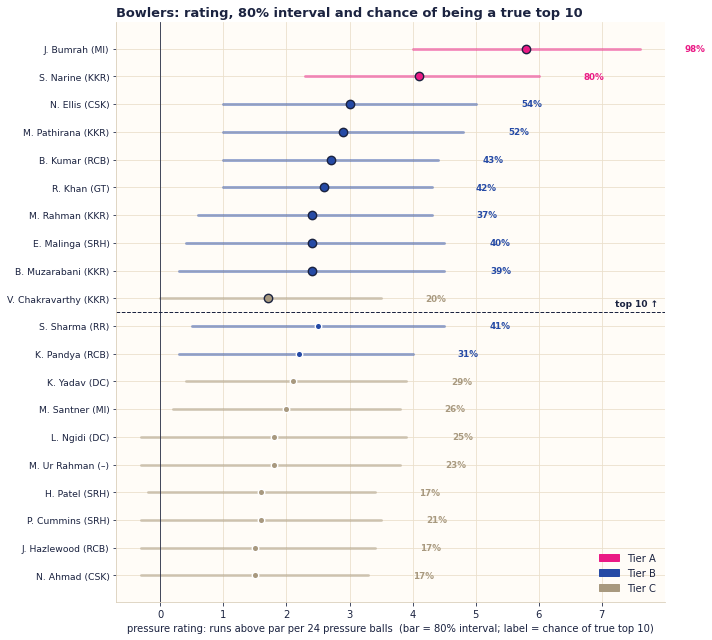

In [16]:
forest(bowl, "Bowlers: rating, 80% interval and chance of being a true top 10", "runs above par per 24 pressure balls")

**Reading it.** Bumrah stands clear (98% chance of a true top 10) with Narine next (80%); both are Tier A. Beyond them the intervals overlap heavily, which is normal for bowlers: each has fewer pressure balls than a batter, so each rating carries more noise. This is why the selection rule uses several cut-offs rather than trusting any one ordering.

### 3.3 The full eligible pool: where our picks sit

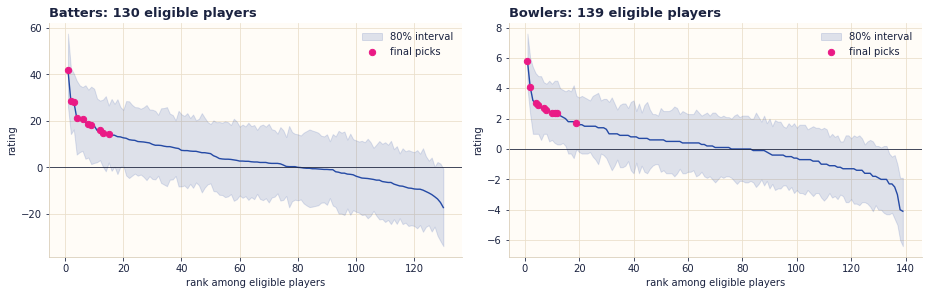

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, key, ttl in [(ax[0], "pool_bat", "Batters"), (ax[1], "pool_bowl", "Bowlers")]:
    P = pd.DataFrame(D[key]).sort_values("rating", ascending=False).reset_index(drop=True); x = P.index + 1
    a.fill_between(x, P.lo, P.hi, color=BLUE, alpha=.15, label="80% interval"); a.plot(x, P.rating, color=BLUE, lw=1.4)
    pk = P[P.status == "pick"]; a.scatter(pk.index + 1, pk.rating, color=PINK, s=40, zorder=3, label="final picks"); a.axhline(0, color=INK, lw=.8)
    a.set_xlabel("rank among eligible players"); a.set_ylabel("rating"); a.set_title(f"{ttl}: {len(P)} eligible players"); a.legend()
plt.tight_layout(); plt.show()

**So what.** Ratings fall steeply at the top and flatten into a long middle where nearly everyone is within noise of average (0). Our ten sit in the steep part. It also shows why a longer list would not be more useful:
beyond roughly 20, differences between players are smaller than the uncertainty around each.

### 3.4 Batter dominance by delivery type (leading batters)

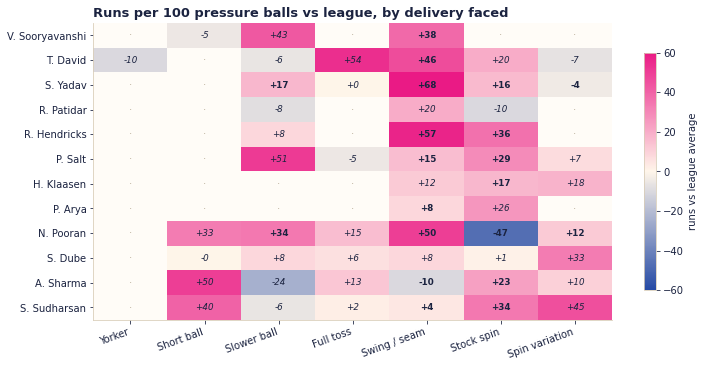

In [18]:
dv = pd.DataFrame(D["delivery"]["rows"], columns=["name"] + D["delivery"]["cols"]).set_index("name")
val = dv.applymap(lambda c: c[0] if isinstance(c, list) else np.nan); nb = dv.applymap(lambda c: c[1] if isinstance(c, list) else 0)
val.index = [short(n) for n in val.index]
fig, ax = plt.subplots(figsize=(10.5, 5.2))
cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#FFF6EA", PINK]); im = ax.imshow(val.values, cmap=cmap, vmin=-60, vmax=60, aspect="auto")
ax.set_xticks(range(val.shape[1])); ax.set_xticklabels(val.columns, rotation=20, ha="right"); ax.set_yticks(range(val.shape[0])); ax.set_yticklabels(val.index); ax.grid(False)
for (r, c), v in np.ndenumerate(val.values):
    if np.isnan(v): ax.text(c, r, "·", ha="center", va="center", color="#B7AB95")
    else: ax.text(c, r, f"{v:+.0f}", ha="center", va="center", fontsize=8.8, fontweight="bold" if nb.values[r, c] >= 40 else "normal", style="normal" if nb.values[r, c] >= 40 else "italic", color=INK)
ax.set_title("Runs per 100 pressure balls vs league, by delivery faced"); plt.colorbar(im, label="runs vs league average", shrink=.8); plt.tight_layout(); plt.show()

**How to read it.** Pink = scores above the league average against that delivery type under pressure; blue = below. Bold means 40+ pressure balls (more reliable); italic means a thin sample, so treat with care; a dot means too few balls to say.
The rows are the final-pick batters plus the next few names on the list. Use it for *plans*: you can see which batters would be a risk against the yorker or the slower ball, and who attacks spin variations. It does not change the ranking; it explains it.

### 3.5 Bowler profiles (final-pick bowlers)

In [19]:
pr = bowl[bowl.status == "pick"].set_index("name")["prof"].apply(pd.Series)
pr.index = [short(n) for n in pr.index]
pr = pr.rename(columns={"dot%_pressure": "Dot-ball % (pressure)", "death_yorker%": "Death yorker %", "death_slower%": "Death slower-ball %", "death_saved_per24": "Runs saved at death /24", "breaker_share%": "Breakthrough share %", "vs_left_hand": "Vs left-hand (runs/24)", "vs_right_hand": "Vs right-hand (runs/24)"})
cm_w = LinearSegmentedColormap.from_list("w", ["#FFFFFF", "#F6B3D2"])
display(pr.round(1).style.background_gradient(cmap=cm_w, axis=0).format("{:.1f}", na_rep="-"))

,Dot-ball % (pressure),Death yorker %,Death slower-ball %,Runs saved at death /24,Breakthrough share %,Vs left-hand (runs/24),Vs right-hand (runs/24)
J. Bumrah,41.9,17.5,23.6,10.3,20.0,10.6,7.2
S. Narine,40.0,0.0,0.0,9.2,34.4,4.0,6.5
N. Ellis,32.3,7.8,35.5,2.7,41.4,6.5,4.5
M. Pathirana,33.9,11.7,23.4,5.5,32.9,4.6,3.6
B. Kumar,37.8,15.3,23.1,4.0,18.3,3.6,2.7
R. Khan,34.5,0.3,0.0,0.2,29.4,4.4,2.0
M. Rahman,33.1,7.1,40.7,3.2,26.6,5.0,3.9
E. Malinga,41.1,9.5,29.6,5.3,41.8,2.8,3.7
B. Muzarabani,31.4,2.3,20.7,2.5,13.0,2.9,4.7
V. Chakravarthy,36.0,0.0,0.0,-1.8,30.4,1.5,2.1


**So what.** This is the "how" behind each bowler's number: who gets dot balls, who bowls yorkers at the death, who is a wicket-taker versus a run-saver, and who is better against left- or right-handers.
It is the starting point for role assignment, for example a death specialist (high death yorker and slower-ball use) versus a bridge bowler.

---
# Part 4 · Predict: how sure are we?

### 4.1 Simulating the selection 4,000 times

Batters : expected number of our 10 picks that are truly top 10 = 5.2   (in 90% of worlds between 3 and 7)
Bowlers : expected number of our 10 picks that are truly top 10 = 5.0   (in 90% of worlds between 3 and 7)


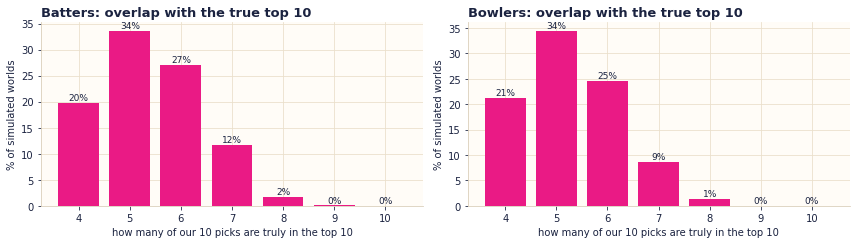

In [20]:
# IDEA. Each player's true rating is uncertain: we treat it as a bell curve (mean = shrunk rating, spread = posterior sd).
# We draw a "possible world" 4,000 times, rank everyone in that world, and count how often each player lands in the top 10.
# The share of worlds is his "chance of being a true top 10". This is a Monte Carlo simulation.
rng = np.random.default_rng(2026)
def simulate(rows, n=4000):
    mu = np.array([r["mu"] for r in rows]); sd = np.array([r["sd"] for r in rows])
    draws = rng.normal(mu, sd, (n, len(rows)))
    ranks = (-draws).argsort(1).argsort(1) + 1           # rank 1 = best in that simulated world
    return ranks
out = {}
for key, lab in [("bat", "batters"), ("bowl", "bowlers")]:
    rows = D["sim"][key]; R = simulate(rows); picks = np.array([r["pick"] for r in rows])
    out[key] = (rows, R, picks)
    hits = (R[:, picks] <= 10).sum(1)                    # how many of OUR 10 are truly top 10 in each world
    print(f"{lab.title():8s}: expected number of our 10 picks that are truly top 10 = {hits.mean():.1f}   "
          f"(in 90% of worlds between {np.percentile(hits, 5):.0f} and {np.percentile(hits, 95):.0f})")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, key, ttl in [(ax[0], "bat", "Batters"), (ax[1], "bowl", "Bowlers")]:
    rows, R, picks = out[key]; hits = (R[:, picks] <= 10).sum(1); vals = np.arange(4, 11); fr = [(hits == v).mean() * 100 for v in vals]
    a.bar(vals, fr, color=PINK); [a.text(v, f + .5, f"{f:.0f}%", ha="center", fontsize=9) for v, f in zip(vals, fr)]
    a.set_xlabel("how many of our 10 picks are truly in the top 10"); a.set_ylabel("% of simulated worlds"); a.set_title(f"{ttl}: overlap with the true top 10")
plt.tight_layout(); plt.show()

**So what.** This is the honest scorecard. Even a well-built list will not match the "true" top 10 perfectly when samples are small. In this simulation we should typically expect about **five of our ten** batters, and about five of our ten bowlers, to land in the true top 10 (between 3 and 7 in 90% of simulated worlds). The misses are mostly players who would rank 11th to 15th, close neighbours rather than weak names, and the reserve and watchlist exist for that reason. The simulation takes the shrunk ratings as the centre of each player's range, so treat it as a cautious, noise-only view of how much luck the list carries. It is the reason every name carries a chance next to it.

### 4.2 How the rank of each pick could wobble

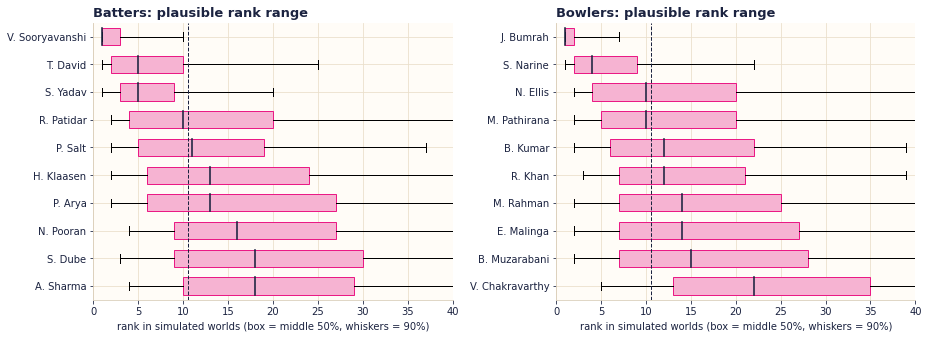

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
for a, key, ttl in [(ax[0], "bat", "Batters"), (ax[1], "bowl", "Bowlers")]:
    rows, R, picks = out[key]; idx = np.where(picks)[0]; order = idx[np.argsort([rows[i]["mu"] * -1 for i in idx])]
    data = [np.clip(R[:, i], 1, 40) for i in order]
    bp = a.boxplot(data, vert=False, whis=(5, 95), showfliers=False, patch_artist=True, widths=.62, medianprops=dict(color=INK, lw=1.6))
    for b in bp["boxes"]: b.set(facecolor="#F6B3D2", edgecolor=PINK)
    a.set_yticks(range(1, len(order) + 1)); a.set_yticklabels([short(rows[i]["name"]) for i in order]); a.invert_yaxis(); a.axvline(10.5, color=INK, ls="--", lw=1)
    a.set_xlim(0, 40); a.set_xlabel("rank in simulated worlds (box = middle 50%, whiskers = 90%)"); a.set_title(f"{ttl}: plausible rank range")
plt.tight_layout(); plt.show()

**So what.** The tight boxes at the top (for example Sooryavanshi, Bumrah, Narine) are near-certain top-10 names. The long boxes lower down show the players whose placement depends on luck of the draw. This is the visual version of the Tier A, B and C labels.

### 4.3 Anatomy of a pressure chase: Rajasthan Royals v Kolkata Knight Riders, 2024

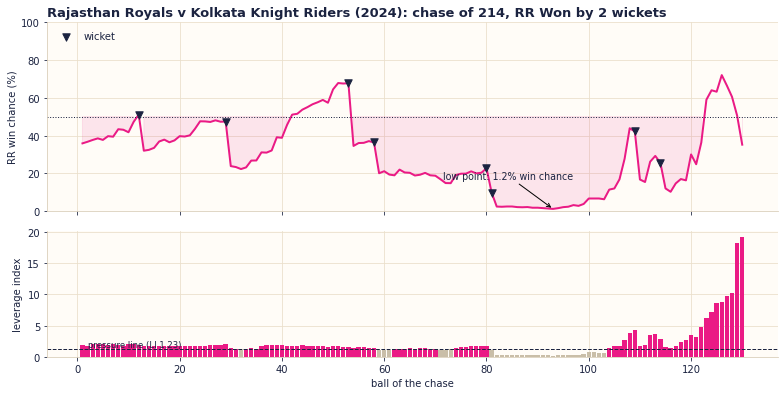

In [22]:
R0 = D["replays2"][0]; Bb = pd.DataFrame(R0["balls"], columns=["over", "ball", "wp", "li", "runs", "wicket", "six", "four", "legal"])
Bb["t"] = np.arange(1, len(Bb) + 1); ov = Bb.over + Bb.ball / 8
fig, ax = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
ax[0].plot(Bb.t, Bb.wp * 100, color=PINK, lw=2); ax[0].axhline(50, color=INK, ls=":", lw=1); ax[0].fill_between(Bb.t, Bb.wp * 100, 50, where=Bb.wp * 100 < 50, color=PINK, alpha=.1)
w = Bb[Bb.wicket == 1]; ax[0].scatter(w.t, w.wp * 100, color=INK, marker="v", s=55, zorder=3, label="wicket")
ax[0].annotate(f"low point: {R0['minwp']*100:.1f}% win chance", (Bb.wp.idxmin() + 1, Bb.wp.min() * 100), xytext=(-110, 30), textcoords="offset points", arrowprops=dict(arrowstyle="->"), fontsize=9.5)
ax[0].set_ylabel("RR win chance (%)"); ax[0].set_ylim(0, 100); ax[0].legend(loc="upper left"); ax[0].set_title(f"{R0['title']} ({R0['year']}): chase of {R0['target']}, {R0['result'].replace('Rajasthan Royals ', 'RR ')}")
ax[1].bar(Bb.t, Bb.li, color=np.where(Bb.li >= D["lev"]["thr"]["20"], PINK, "#C9BEA8"), width=.85); ax[1].set_ylabel("leverage index"); ax[1].set_xlabel("ball of the chase")
ax[1].axhline(D["lev"]["thr"]["20"], color=INK, ls="--", lw=1); ax[1].text(2, D["lev"]["thr"]["20"] + .4, "pressure line (LI 1.23)", fontsize=8.5)
plt.tight_layout(); plt.show()

**So what.** Win chance fell to about 1% and the game was still won: this is the shape of a great escape. The bottom panel shows which balls the rating would count: a large target keeps leverage above the pressure line for most of the chase (pink bars), the stretch from about ball 82 to 105 turns grey because the chase looked lost and one ball could not change much, and then leverage explodes in the last 25 balls, peaking at about 19 times an average ball. A single over of heroics there is worth more rating than dozens of early balls, which is exactly the point of the method. In the dashboard, the Matchups tab replays this ball by ball for 11 chases (7 of them Royals games).

---
# Part 5 · Act: what Rajasthan Royals should do

### 5.1 Where Royals are strong and weak under pressure

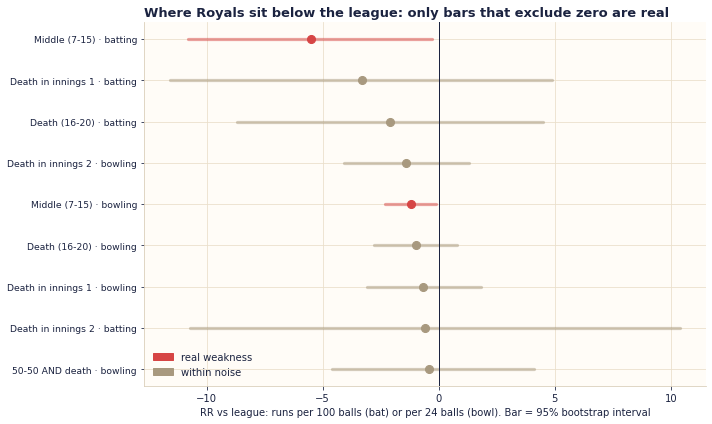

situation,RR gap,low,high,verdict,balls
Middle (7-15) · batting,-5.500000,-10.800000,-0.300000,real weakness,4033
Death in innings 1 · batting,-3.300000,-11.600000,4.900000,within noise,1134
Death (16-20) · batting,-2.100000,-8.700000,4.500000,within noise,1966
Death in innings 2 · bowling,-1.400000,-4.100000,1.300000,within noise,1056
Middle (7-15) · bowling,-1.200000,-2.300000,-0.100000,real weakness,4277
Death (16-20) · bowling,-1.000000,-2.800000,0.800000,within noise,2250
Death in innings 1 · bowling,-0.700000,-3.100000,1.800000,within noise,1194
Death in innings 2 · batting,-0.600000,-10.700000,10.400000,within noise,832


In [23]:
G = pd.DataFrame(D["rr"]["gaps"]); G["label"] = G.s + " · " + G.side.map({"bat": "batting", "bowl": "bowling"})
G = G[G.gap <= 0].sort_values("gap", ascending=False).reset_index(drop=True)   # only situations where RR is at or below the league
fig, ax = plt.subplots(figsize=(10, 6))
for i, r in G.iterrows():
    col = {"real strength": GREEN, "real weakness": RED}.get(r.v, GREY)
    ax.plot([r.lo, r.hi], [i, i], color=col, lw=3.2, alpha=.5, solid_capstyle="round"); ax.scatter(r.gap, i, color=col, s=65, zorder=3)
ax.axvline(0, color=INK, lw=1); ax.set_yticks(range(len(G))); ax.set_yticklabels(G.label, fontsize=9.3)
ax.set_xlabel("RR vs league: runs per 100 balls (bat) or per 24 balls (bowl). Bar = 95% bootstrap interval"); ax.set_title("Where Royals sit below the league: only bars that exclude zero are real")
ax.legend(handles=[Patch(color=RED, label="real weakness"), Patch(color=GREY, label="within noise")], loc="lower left"); plt.tight_layout(); plt.show()
display(G.sort_values("gap")[["label", "gap", "lo", "hi", "v", "n"]].rename(columns={"label": "situation", "gap": "RR gap", "lo": "low", "hi": "high", "v": "verdict", "n": "balls"}).round(1).reset_index(drop=True).head(8).style.hide(axis="index"))

**So what.** Gaps are measured against the league and only called real if the interval clears zero. Royals' **middle-overs batting (−5.5 per 100 balls, interval −10.8 to −0.3)** is a real weakness, and it is worst against pace (about −8.6).
Their **middle-overs bowling (−1.2 per 24 balls)** is also real but smaller. Every other situation where Royals sit below the league is within noise, and the notebook says so rather than inventing a story.

### 5.2 Has this been steady or a one-season blip?

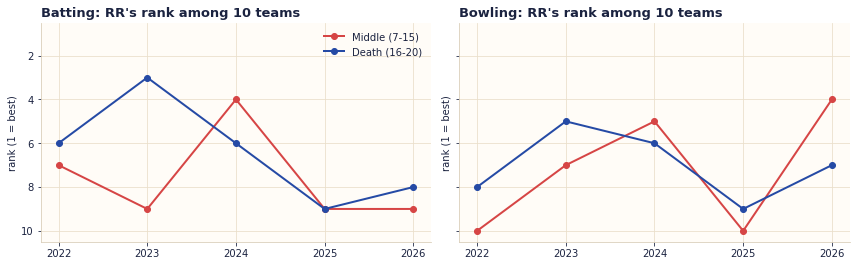

In [24]:
Sn = pd.DataFrame(D["rr"]["seasons"]); fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, side, ttl in [(ax[0], "bat", "Batting: RR's rank among 10 teams"), (ax[1], "bowl", "Bowling: RR's rank among 10 teams")]:
    for s_, c in [("Middle (7-15)", RED), ("Death (16-20)", BLUE)]:
        q = Sn[(Sn.side == side) & (Sn.s == s_)].sort_values("y")
        if len(q): a.plot(q.y, q["rank"], marker="o", color=c, lw=2, label=s_)
    a.set_ylim(10.5, .5); a.set_xticks(sorted(Sn.y.unique())); a.set_title(ttl); a.set_ylabel("rank (1 = best)")
ax[0].legend(); plt.tight_layout(); plt.show()

**So what.** A real weakness should repeat. Middle-overs batting has ranked 7th, 9th, 4th, 9th and 9th of 10 over the five seasons: low in four of five, which supports the case. Middle-overs bowling is more up and down (10th, 7th, 5th, 10th, 4th), so the batting gap is the firmer finding. Death-over ranks wander without a settled pattern, consistent with their gaps being within noise.

### 5.3 Which of our picks fill that gap?

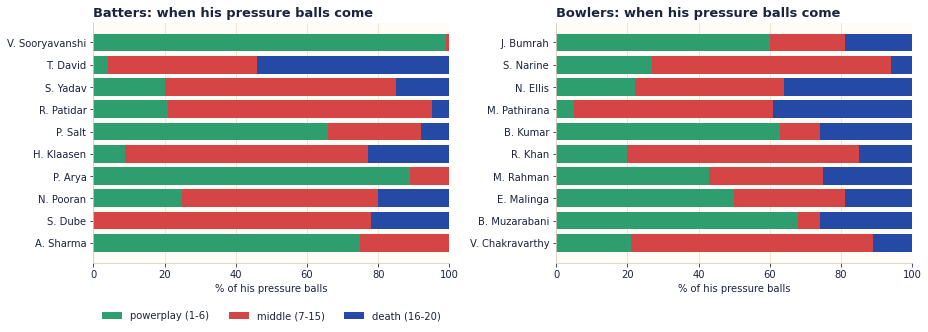

Batters with the largest middle-overs share of pressure balls: S. Dube 78%, R. Patidar 74%, H. Klaasen 68%, S. Yadav 65%, N. Pooran 55%
Bowlers with the largest middle-overs share of pressure balls: V. Chakravarthy 68%, S. Narine 67%, R. Khan 65%, M. Pathirana 56%, N. Ellis 42%


name,side,team,what he adds for RR
Vaibhav Sooryavanshi,batter,RR,At RR already · Powerplay hitting
Tim David,batter,RCB,Finisher: late-overs hitting
Suryakumar Yadav,batter,MI,Middle overs vs pace: RR's weakest spot
Rajat Patidar,batter,RCB,Middle-overs spin-hitter
Phil Salt,batter,RCB,Powerplay hitting
Heinrich Klaasen,batter,SRH,Middle-overs spin-hitter
Priyansh Arya,batter,PBKS,Powerplay hitting
Nicholas Pooran,batter,LSG,Middle-overs accelerator
Shivam Dube,batter,CSK,Middle-overs spin-hitter
Abhishek Sharma,batter,SRH,Powerplay hitting


In [25]:
def mix(df, ttl, ax):
    t = df[df.status == "pick"].copy(); t["mid"] = (1 - t.ppShare - t.lateShare).clip(lower=0)
    t = t.iloc[::-1]; y = np.arange(len(t))
    ax.barh(y, t.ppShare * 100, color=GREEN, label="powerplay (1-6)"); ax.barh(y, t.mid * 100, left=t.ppShare * 100, color=RED, label="middle (7-15)")
    ax.barh(y, t.lateShare * 100, left=(t.ppShare + t.mid) * 100, color=BLUE, label="death (16-20)")
    ax.set_yticks(y); ax.set_yticklabels([short(n) for n in t.name]); ax.set_xlim(0, 100); ax.set_xlabel("% of his pressure balls"); ax.set_title(ttl)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8)); mix(bat, "Batters: when his pressure balls come", ax[0]); mix(bowl, "Bowlers: when his pressure balls come", ax[1])
ax[0].legend(loc="lower center", bbox_to_anchor=(.5, -.28), ncol=3); plt.tight_layout(); plt.show()
for df_, lab in [(bat, "Batters"), (bowl, "Bowlers")]:
    t_ = df_[df_.status == "pick"].assign(middle=lambda x: (1 - x.ppShare - x.lateShare).clip(lower=0) * 100).sort_values("middle", ascending=False)
    print(lab, "with the largest middle-overs share of pressure balls:", ", ".join(f"{short(n)} {m:.0f}%" for n, m in zip(t_.name.head(5), t_.middle.head(5))))
fit = pd.concat([bat.assign(side="batter"), bowl.assign(side="bowler")]); fit = fit[(fit.status == "pick")][["name", "side", "team", "fit"]].rename(columns={"fit": "what he adds for RR"})
fit["what he adds for RR"] = fit["what he adds for RR"].str.replace("Powerplay power: extends RR's best phase", "Powerplay hitting", regex=False).str.replace(" extends RR's best phase", "", regex=False)
display(fit.reset_index(drop=True).style.hide(axis="index"))

**So what.** The bars show *when* each pick faces his pressure balls, and the printout above ranks them by middle-overs share. Because Royals' firmest gap is **middle-overs batting**, the most relevant batters are those with a high rating and a large middle-overs share, such as Dube, Patidar, Klaasen and Suryakumar Yadav; on the bowling side Narine, Rashid Khan, Chakravarthy and Pathirana do most of their pressure work in the middle. The table lists what each pick adds for Royals. Treat it as a shortlist for conversations, not an auction instruction.

---
# Summary and recommendations

**What we found**
1. **Pressure is concentrated.** One ball in five carries 2.1× its fair share of a match's swing; 93% of those balls occur in chases.
2. **Wickets must be priced by phase.** An early wicket costs about 4× a death-over wicket, so flat penalties distort rankings.
3. **We tested tempting shortcuts and dropped them.** Match stakes do not change how often pressure arises, and death-over variety shows no relationship with runs saved. Neither is used.
4. **The top 10 lists are stable to the definition of pressure.** 5 batters and 6 bowlers are top 10 under all four cut-offs; everyone else passes at least two.
5. **Uncertainty is real and reported.** In the simulation about five of ten names in each list land in the true top 10 and the rest are close neighbours, which is why every player has a chance next to his name and why there is a reserve.

**What it means for Rajasthan Royals**
* The **middle overs** are where Royals lose ground under pressure: batting is the firmer finding (about −5.5 runs per 100 balls, worst against pace), bowling is a smaller gap. Prioritise players who rate highly *and* do their pressure work in overs 7 to 15.
* Prefer **Tier A** names for certainty; use **Tier B/C** names where role fit (from the profiles and gap tables) tips the balance.

**Limits to keep in mind**
* Samples are small by design (pressure balls only), so intervals are wide and the order inside Tier B/C is soft.
* The win-probability model is strong in chases (AUC 0.90) but weaker for first innings (AUC 0.71); first-innings pressure is treated cautiously.
* Ratings are **descriptive**: they say who has handled pressure best in this data, not who will be best next season or at what price.
* Eligibility thresholds, the 60/40 win-chance filter and the 2-of-4 rule are our choices; the robustness checks above show how much they matter.

---
### Where everything lives in this repository
| Item | Purpose |
|---|---|
| `README.md` | Overview and how to run |
| `data/pressure_rating_results.json` | Output of the full pipeline that this notebook reads |
| Pipeline notebooks / scripts | Raw ball-by-ball cleaning, win-probability model, leverage, par engine, ratings, simulations |
| Methodology PDF | The full written method, assumptions and checks |
| Interactive dashboard | The same findings with filters and head-to-head comparison |